# EDA snapshots

Three snapshots over the Phase 2 stores produced by the end-to-end
verification run:

1. **Interaction-matrix sparsity** — how thinly the listening events
   spread across the user x track matrix.
2. **Genre distribution** — genres attached to events by the catalog
   enrichment, alongside the genres held in the catalog itself.
3. **Catalog growth over time** — releases per year from the
   MusicBrainz snapshot.

All figures are generated from `data/events_store/` (Parquet) and
`data/catalog_store/` (Delta); no numbers below are hard-coded.

In [1]:
import os
import sys
from pathlib import Path

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

%matplotlib inline
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

from src.common.config import load_config
from src.ingestion.events_stream import build_spark

cfg = load_config()
spark = build_spark(cfg)
spark.conf.set("spark.sql.shuffle.partitions", "8")
spark.sparkContext.setLogLevel("ERROR")

events = spark.read.parquet(str(ROOT / cfg["paths"]["events_store"]))
catalog = spark.read.format("delta").load(str(ROOT / cfg["paths"]["catalog_store"]))
print(f"events rows: {events.count()}")
print(f"catalog releases: {catalog.count()}")

events rows: 2600
catalog releases: 107


## 1. Interaction-matrix sparsity

Each observed (user, songId) pair is one filled cell of the
interaction matrix. Density is filled cells divided by the full
user x track rectangle; the heatmap shows the busiest slice of the
matrix (top users by activity against top tracks by activity) with
one mark per observed pair.

In [2]:
users = events.select("userId").distinct().count()
tracks = events.select("songId").distinct().count()
pairs = events.select("userId", "songId").distinct().count()
density = pairs / (users * tracks)
print(f"users: {users}")
print(f"distinct tracks: {tracks}")
print(f"observed (user, track) pairs: {pairs}")
print(f"matrix cells: {users * tracks}")
print(f"density: {density:.4%}")
print(f"sparsity: {1 - density:.4%}")

users: 52
distinct tracks: 2176
observed (user, track) pairs: 2196
matrix cells: 113152
density: 1.9408%
sparsity: 98.0592%


C:\Users\aarya\anaconda3\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [UNSUPPORTED_PACKAGE_VERSION] PyArrow >= 18.0.0 must be installed; however, your version is 14.0.2.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


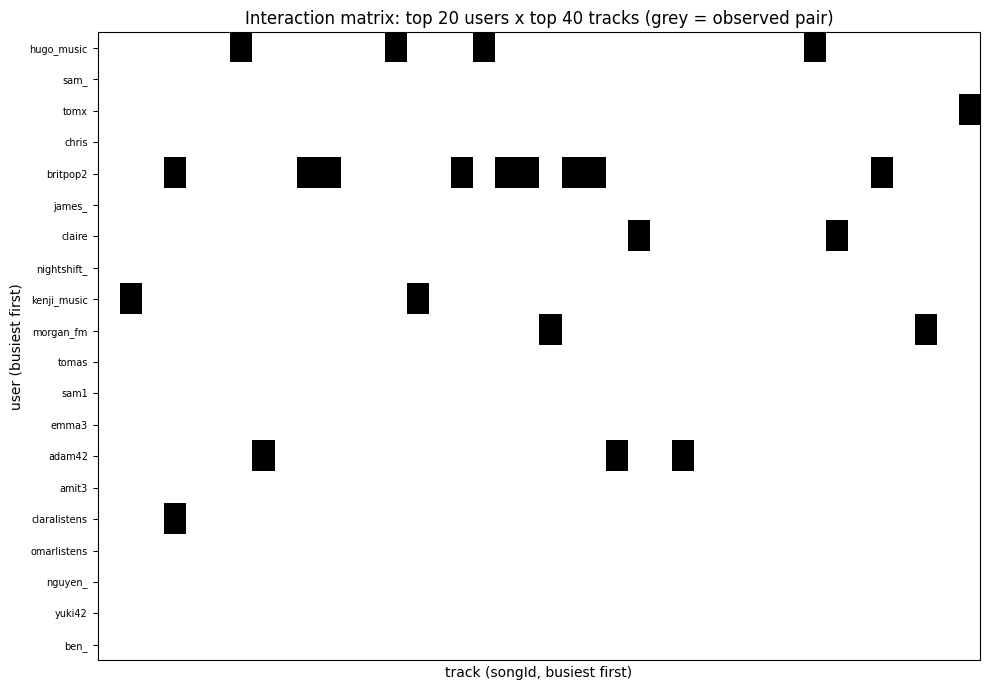

In [3]:
top_users = [
    r["userId"]
    for r in events.groupBy("userId")
    .count()
    .orderBy(F.desc("count"))
    .limit(20)
    .collect()
]
top_tracks = [
    r["songId"]
    for r in events.groupBy("songId")
    .count()
    .orderBy(F.desc("count"))
    .limit(40)
    .collect()
]
slice_pdf = (
    events.filter(F.col("userId").isin(top_users) & F.col("songId").isin(top_tracks))
    .groupBy("userId", "songId")
    .count()
    .toPandas()
)
matrix = (
    slice_pdf.pivot(index="userId", columns="songId", values="count")
    .reindex(index=top_users, columns=top_tracks, fill_value=0)
    .fillna(0)
)
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(matrix.values > 0, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_title("Interaction matrix: top 20 users x top 40 tracks (grey = observed pair)")
ax.set_xlabel("track (songId, busiest first)")
ax.set_ylabel("user (busiest first)")
ax.set_xticks([])
ax.set_yticks(range(len(top_users)))
ax.set_yticklabels(top_users, fontsize=7)
plt.tight_layout()
plt.show()

## 2. Genre distribution

Enrichment only attaches a genre when the event's artist matches an
artist in the catalog snapshot, so the event-side distribution
covers the matched subset. The catalog-side distribution shows the
genres available across all snapshot releases.

In [4]:
event_genres = (
    events.filter(F.col("genre").isNotNull())
    .groupBy("genre")
    .count()
    .orderBy(F.desc("count"))
)
catalog_genres = (
    catalog.filter(F.col("genre").isNotNull())
    .groupBy("genre")
    .count()
    .orderBy(F.desc("count"))
)
print(f"events with genre: {events.filter(F.col('genre').isNotNull()).count()}")
print(f"catalog releases with genre: {catalog.filter(F.col('genre').isNotNull()).count()}")
print("\ntop event genres:")
event_genres.show(15, truncate=False)
print("top catalog genres:")
catalog_genres.show(15, truncate=False)

events with genre: 61
catalog releases with genre: 20

top event genres:
+--------------------+-----+
|genre               |count|
+--------------------+-----+
|censored album cover|61   |
+--------------------+-----+

top catalog genres:
+------------------------------+-----+
|genre                         |count|
+------------------------------+-----+
|electronic                    |5    |
|music video                   |4    |
|censored album cover          |3    |
|blues                         |2    |
|vocal jazz                    |2    |
|anthropomorphic nsfw cover art|1    |
|folk                          |1    |
|post-rock                     |1    |
|score                         |1    |
+------------------------------+-----+



C:\Users\aarya\anaconda3\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [UNSUPPORTED_PACKAGE_VERSION] PyArrow >= 18.0.0 must be installed; however, your version is 14.0.2.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
C:\Users\aarya\anaconda3\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [UNSUPPORTED_PACKAGE_VERSION] PyArrow >= 18.0.0 must be installed; however, your version is 14.0.2.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


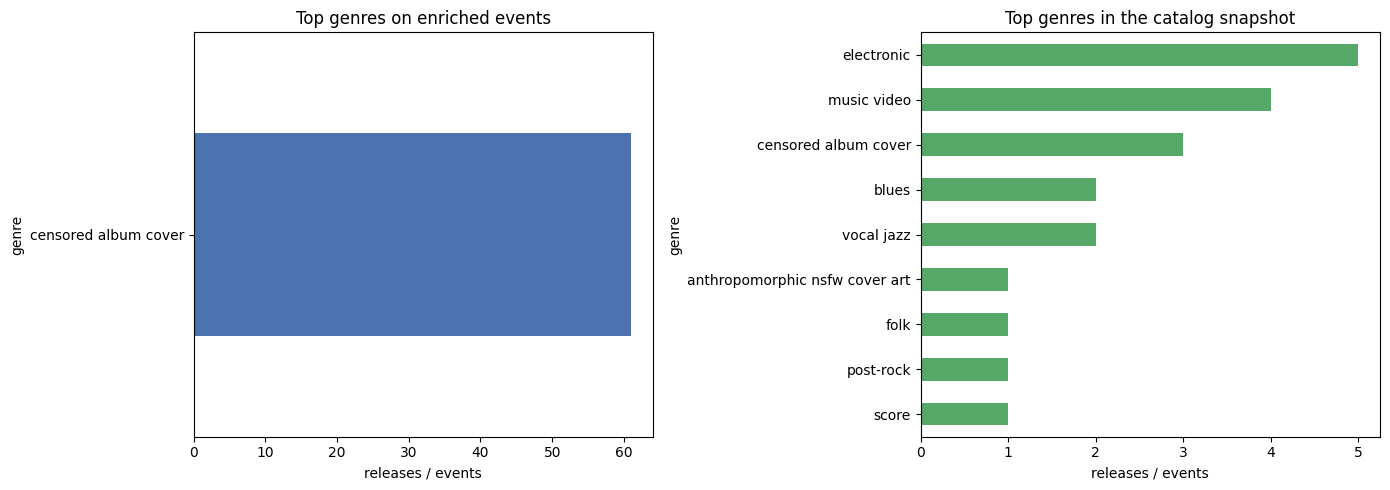

In [5]:
event_pdf = event_genres.limit(15).toPandas()
catalog_pdf = catalog_genres.limit(15).toPandas()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if not event_pdf.empty:
    event_pdf.iloc[::-1].plot.barh(x="genre", y="count", ax=axes[0], legend=False, color="#4C72B0")
    axes[0].set_title("Top genres on enriched events")
else:
    axes[0].text(0.5, 0.5, "no enriched events", ha="center", va="center")
    axes[0].set_title("Top genres on enriched events")
if not catalog_pdf.empty:
    catalog_pdf.iloc[::-1].plot.barh(x="genre", y="count", ax=axes[1], legend=False, color="#55A868")
    axes[1].set_title("Top genres in the catalog snapshot")
else:
    axes[1].text(0.5, 0.5, "no catalog genres", ha="center", va="center")
    axes[1].set_title("Top genres in the catalog snapshot")
for ax in axes:
    ax.set_xlabel("releases / events")
plt.tight_layout()
plt.show()

## 3. Catalog growth over time

Releases per release year from the catalog snapshot, plus the
cumulative total, to show how the snapshot accumulates history.

In [6]:
by_year = (
    catalog.filter(F.col("releaseDate").isNotNull())
    .withColumn("year", F.substring("releaseDate", 1, 4).cast("int"))
    .filter(F.col("year").between(1950, 2100))
    .groupBy("year")
    .count()
    .orderBy("year")
)
year_pdf = by_year.toPandas()
year_pdf["cumulative"] = year_pdf["count"].cumsum()
print(f"years covered: {year_pdf['year'].min()} - {year_pdf['year'].max()}")
print(f"dated releases: {int(year_pdf['count'].sum())}")
year_pdf.tail(10)

C:\Users\aarya\anaconda3\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [UNSUPPORTED_PACKAGE_VERSION] PyArrow >= 18.0.0 must be installed; however, your version is 14.0.2.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


years covered: 2013 - 2026
dated releases: 104


,year,count,cumulative
0,2013,1,1
1,2021,3,4
2,2026,100,104


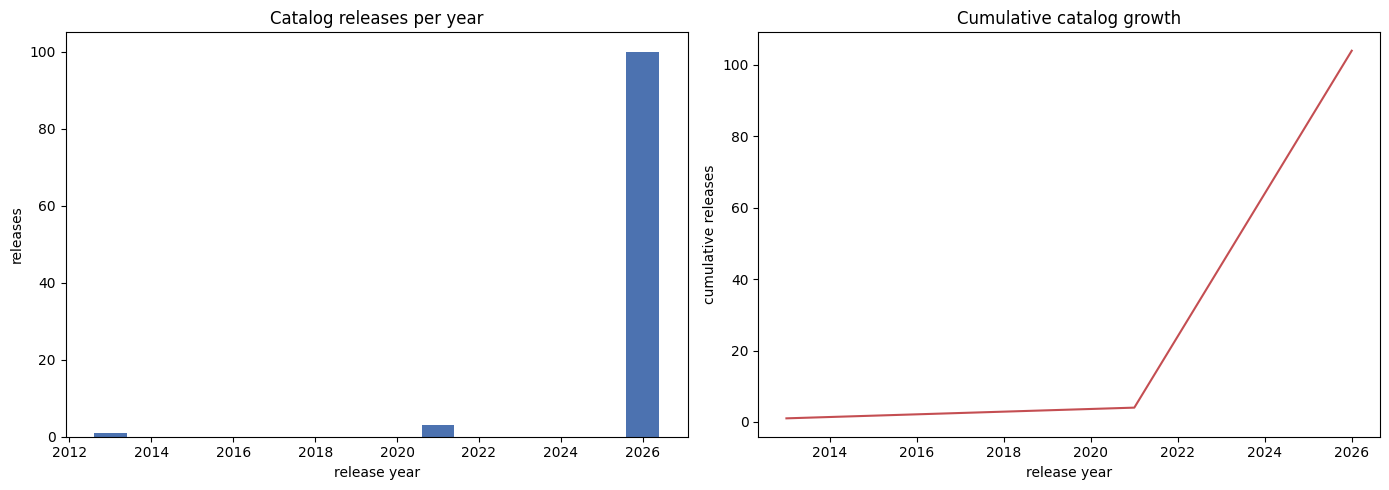

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(year_pdf["year"], year_pdf["count"], color="#4C72B0")
axes[0].set_title("Catalog releases per year")
axes[0].set_xlabel("release year")
axes[0].set_ylabel("releases")
axes[1].plot(year_pdf["year"], year_pdf["cumulative"], color="#C44E52")
axes[1].set_title("Cumulative catalog growth")
axes[1].set_xlabel("release year")
axes[1].set_ylabel("cumulative releases")
plt.tight_layout()
plt.show()

### Snapshot notes

- The interaction matrix is expected to be near-empty: each user
  contributes a handful of recent scrobbles out of a much larger
  track vocabulary, which is exactly the cold-start pressure the
  discovery engine has to work against.
- Event-side genres only exist for artists present in the catalog
  snapshot; a fuller catalog (or a bootstrap load) widens that
  coverage.
- The catalog snapshot mixes recent releases with deep back
  catalogue, so the growth chart is a property of the polling
  window rather than of the market.